# Phân tích các yếu tố ảnh hưởng đến điểm cuối kỳ (G3) — Notebook hướng dẫn chạy tuần tự

**Câu hỏi chính:** Thời gian học (`studytime`), số buổi nghỉ (`absences`), sự hỗ trợ của gia đình (`famsup`) và điểm giữa kỳ (`G1`, `G2`) liên quan thế nào đến điểm cuối kỳ `G3` của học sinh môn Toán?

**Dữ liệu:** UCI *Student Performance* — `student-mat.csv` (Toán, 395 học sinh, là bộ phân tích chính) và `student-por.csv` (Tiếng Bồ Đào Nha, 649 học sinh, chỉ dùng để *kiểm tra lại* quy tắc cảnh báo rủi ro).

---
### Cách dùng notebook này
1. Chạy **từng cell theo thứ tự từ trên xuống** (chọn cell → `Shift + Enter`), hoặc chạy cả notebook bằng *Run All*. **Không nhảy cóc**: cell phía sau dùng biến do cell phía trước tạo ra.
2. Mỗi phần gồm: **(a) ô giải thích** → **(b) ô code có chú thích `#` từng dòng** → **(c) ô "Đọc kết quả"** nói rõ con số nghĩa là gì.
3. Notebook **không cần internet** và **không ghi đè file nào** của project (phần chạy pipeline đầy đủ ghi vào thư mục tạm).
4. Nếu bị lỗi giữa chừng: `Kernel → Restart & Run All`.

### Mục lục
| # | Nội dung |
|---|---|
| 1 | Chuẩn bị môi trường & import thư viện |
| 2 | Kiểm tra file dữ liệu |
| 3 | Đọc dữ liệu thô (load) |
| 4 | Kiểm tra chất lượng dữ liệu |
| 5 | Làm sạch & tạo cột mới (4 hàm cơ bản) |
| 6 | Phát hiện học sinh "dropout suspect" (G3 = 0) |
| 7 | Thống kê mô tả theo nhóm (EDA) |
| 8 | Vẽ 3 biểu đồ |
| 9 | Tương quan G1 / G2 / G3 |
| 10 | Kiểm định thống kê (t-test, ANOVA) |
| 11 | Quy tắc cảnh báo rủi ro (Risk Group) + holdout |
| 12 | Chạy pipeline đầy đủ & đối chiếu với phần làm tay |
| 13 | Dữ liệu tham chiếu PISA |
| 14 | Kết luận & hạn chế |

## 1. Chuẩn bị môi trường & import thư viện

| Thư viện | Dùng để làm gì |
|---|---|
| `pandas` | Đọc CSV, lọc, gom nhóm (bảng dữ liệu = `DataFrame`) |
| `numpy` | Tính toán số học trên mảng |
| `matplotlib` | Vẽ biểu đồ |
| `scipy.stats` | Kiểm định thống kê (t-test, ANOVA, tương quan) |
| `data_processor` | Module của project: chứa các hàm tự viết và pipeline đầy đủ |

> Notebook phải được mở **từ thư mục gốc của project** (nơi có file `data_processor.py`) thì dòng `import data_processor` mới chạy được.

In [1]:
# Thư viện chuẩn của Python
import inspect          # xem mã nguồn của một hàm ngay trong notebook
import tempfile         # tạo thư mục tạm (để không ghi đè file của project)
from pathlib import Path  # làm việc với đường dẫn file gọn hơn so với chuỗi

# Thư viện phân tích dữ liệu
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Code của project: các hàm nhỏ + pipeline đầy đủ
import data_processor as dp

# Hiển thị biểu đồ ngay bên dưới cell; hiển thị tối đa 30 cột của bảng
%matplotlib inline
pd.set_option("display.max_columns", 30)

print("pandas", pd.__version__, "| numpy", np.__version__)
print("Import thành công ✔")

pandas 3.0.6 | numpy 2.5.4
Import thành công ✔


## 2. Kiểm tra file dữ liệu

Khai báo đường dẫn tới các file thô và kiểm tra chúng có tồn tại không — nếu thiếu, ta biết ngay thay vì gặp lỗi khó hiểu ở các bước sau.

Có 2 hàm hỗ trợ tải dữ liệu nếu thiếu (đã viết sẵn trong `data_processor.py`, **cần internet**, thường không phải chạy):
- `fetch_uci_raw(RAW)`: tải file zip UCI và giải nén ra `data/raw/`.
- `scrape_pisa_table(...)`: cào bảng PISA từ Wikipedia (mặc định dùng bản cache `pisa_reference.csv`, không gọi mạng).

In [2]:
RAW = Path("data/raw")          # thư mục chứa dữ liệu thô (không bao giờ sửa tay)
MAT_CSV = RAW / "student-mat.csv"   # môn Toán  (bộ phân tích chính)
POR_CSV = RAW / "student-por.csv"   # môn Bồ Đào Nha (bộ kiểm tra lại)
PISA_CSV = RAW / "pisa_reference.csv"             # điểm PISA từng nước (bản cache)
OECD_CSV = RAW / "oecd_pisa2025_table_I1.csv"     # bảng OECD chính thức để đối chiếu

# Kiểm tra từng file: in dấu ✔ nếu có, ✘ nếu thiếu
for path in [MAT_CSV, POR_CSV, PISA_CSV, OECD_CSV]:
    print("✔" if path.exists() else "✘", path)

# Nếu thiếu file UCI thì bỏ dấu # ở dòng dưới để tải về (cần internet):
# dp.fetch_uci_raw(RAW)

✔ data/raw/student-mat.csv
✔ data/raw/student-por.csv
✔ data/raw/pisa_reference.csv
✔ data/raw/oecd_pisa2025_table_I1.csv


## 3. Đọc dữ liệu thô (load)

File CSV của UCI dùng dấu **chấm phẩy `;`** làm ký tự phân tách (không phải dấu phẩy), nên phải truyền `sep=";"`.

Mỗi dòng = một học sinh. Một số cột quan trọng (xem đầy đủ ở `data/raw/student.txt`):

| Cột | Ý nghĩa |
|---|---|
| `G1`, `G2` | Điểm kỳ 1, kỳ 2 (thang 0–20) |
| `G3` | **Điểm cuối kỳ (thang 0–20) — biến cần dự đoán** |
| `studytime` | Thời gian học mỗi tuần: 1 (<2h), 2 (2–5h), 3 (5–10h), 4 (>10h) |
| `absences` | Số buổi nghỉ học |
| `failures` | Số môn đã từng rớt trước đây (0–3) |
| `famsup`, `schoolsup`, `paid` | Có được gia đình / nhà trường hỗ trợ học / học thêm có trả phí không (yes/no) |
| `internet` | Nhà có internet không (yes/no) |

In [3]:
# sep=";"  : CSV của UCI ngăn cách các cột bằng dấu chấm phẩy
mat_raw = pd.read_csv(MAT_CSV, sep=";")
por_raw = pd.read_csv(POR_CSV, sep=";")

# .shape trả về (số dòng, số cột)
print("Toán (mat):", mat_raw.shape, "| Bồ Đào Nha (por):", por_raw.shape)

# .head() xem 5 dòng đầu để làm quen với dữ liệu
mat_raw.head()

Toán (mat): (395, 33) | Bồ Đào Nha (por): (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,...,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,...,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,...,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,...,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,...,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,...,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [4]:
# .dtypes cho biết kiểu dữ liệu từng cột: int64 = số nguyên, object = chữ (văn bản)
# Lưu ý: studytime, G1, G2, G3, absences là SỐ; internet, famsup... là CHỮ ("yes"/"no")
mat_raw[["studytime", "absences", "failures", "internet", "famsup", "G1", "G2", "G3"]].dtypes

studytime    int64
absences     int64
failures     int64
internet       str
famsup         str
G1           int64
G2           int64
G3           int64
dtype: object

**Đọc kết quả:** có 395 học sinh Toán và 649 học sinh Bồ Đào Nha, mỗi người 33 cột. Các cột `yes/no` đang ở dạng chữ nên **chưa tính toán được** — ta sẽ mã hoá thành 1/0 ở bước 5.

> Một số học sinh học cả 2 môn nên xuất hiện trong cả hai file (xem `data/raw/student-merge.R`). Điều này được xử lý ở phần 11 (strict holdout).

## 4. Kiểm tra chất lượng dữ liệu

Trước khi phân tích phải trả lời 4 câu hỏi:
1. Có ô trống (missing) không?
2. Có dòng trùng lặp không?
3. Có giá trị **ngoài miền hợp lệ** không (vd điểm 25 trên thang 20)?
4. Có giá trị bất thường nhưng *vẫn hợp lệ* không (outlier)?

Miền hợp lệ của từng cột được định nghĩa trong `dp.VALID_RANGES` (lấy từ tài liệu `student.txt`).

In [5]:
# 1) Ô trống: isna() đánh dấu ô trống, sum() đếm theo cột, sum() lần nữa cộng tất cả
print("Tổng số ô trống (mat):", int(mat_raw.isna().sum().sum()))

# 2) Dòng trùng lặp hoàn toàn
print("Số dòng trùng lặp (mat):", int(mat_raw.duplicated().sum()))

# 3) Giá trị ngoài miền hợp lệ: duyệt từng cột trong VALID_RANGES = {cột: (min, max)}
print("\nGiá trị ngoài miền hợp lệ:")
tong_ngoai_mien = 0
for col, (lo, hi) in dp.VALID_RANGES.items():
    # between(lo, hi) = True nếu lo <= giá trị <= hi ; dấu ~ đảo ngược → lấy phần NGOÀI miền
    so_loi = int((~mat_raw[col].between(lo, hi)).sum())
    tong_ngoai_mien += so_loi
    if so_loi:
        print(f"  {col}: {so_loi} giá trị ngoài [{lo}, {hi}]")
print("Tổng:", tong_ngoai_mien)

Tổng số ô trống (mat): 0
Số dòng trùng lặp (mat): 0

Giá trị ngoài miền hợp lệ:
Tổng: 0


**Đọc kết quả:** dữ liệu UCI đã khá sạch — không ô trống, không trùng lặp, không giá trị ngoài miền. Vấn đề thật sự của bộ dữ liệu này là **ngữ nghĩa**, không phải lỗi nhập liệu: xem phần 6 (học sinh có `G3 = 0`).

## 5. Làm sạch & tạo cột mới — 4 hàm cơ bản

Project có 4 hàm nhỏ trong `data_processor.py`. Hãy xem mã nguồn của chúng trước khi dùng.

| Hàm | Việc làm |
|---|---|
| `convert_yes_no(x)` | `"yes"` → 1, `"no"` → 0, giá trị lạ → `None` |
| `calc_pass_fail(g3)` | G3 ≥ 10 → `"pass"`, ngược lại `"fail"` |
| `classify_absences(n)` | Nghỉ 0–3 buổi: `low`; 4–9: `medium`; ≥10: `high` |
| `calc_average_grade(g1,g2,g3)` | Trung bình 3 kỳ (chỉ để mô tả, **không** dùng để dự đoán G3 vì có chứa G3 → *target leakage*) |

Các ngưỡng (10, 4, 10, ...) nằm trong tuple `dp.THRESHOLDS` để dễ chỉnh ở một chỗ.

In [6]:
# inspect.getsource in ra mã nguồn của hàm → thấy rõ hàm làm gì mà không cần mở file
print(inspect.getsource(dp.convert_yes_no))
print(inspect.getsource(dp.calc_pass_fail))
print(inspect.getsource(dp.classify_absences))

# Tuple ngưỡng: (PASS_MARK, G_WARN, ABS_MED, ABS_HIGH, FAIL_HIGH)
print("THRESHOLDS =", dp.THRESHOLDS)

def convert_yes_no(value) -> int | None:
    """Encode 'yes'/'no' (case-insensitive, stripped) to 1/0; anything else -> None."""
    text = str(value).strip().lower()
    if text == "yes":
        return 1
    if text == "no":
        return 0
    return None

def calc_pass_fail(g3: float, pass_mark: int = PASS_MARK) -> str:
    """Return 'pass' if G3 >= pass_mark else 'fail'."""
    return "pass" if float(g3) >= pass_mark else "fail"

def classify_absences(n: int) -> str:
    """Bucket absences: low (0-3) / medium (4-9) / high (>=10)."""
    n = int(n)
    if n < ABS_MED:
        return "low"
    if n < ABS_HIGH:
        return "medium"
    return "high"

THRESHOLDS = (10, 10, 4, 10, 2)


In [7]:
# Thử nhanh từng hàm với vài giá trị mẫu để kiểm tra hiểu đúng
print(dp.convert_yes_no("yes"), dp.convert_yes_no(" NO "), dp.convert_yes_no("maybe"))   # 1 0 None
print(dp.calc_pass_fail(9), dp.calc_pass_fail(10))                                        # fail pass
print(dp.classify_absences(3), dp.classify_absences(4), dp.classify_absences(10))         # low medium high

1 0 None
fail pass
low medium high


Bây giờ áp dụng các hàm lên toàn bộ bảng bằng `.map()` / `.apply()` (chạy hàm cho từng phần tử của cột). Ta làm trên **bản sao** (`.copy()`) để giữ nguyên dữ liệu thô.

In [8]:
mat = mat_raw.copy()          # bản sao: sửa mat không làm hỏng mat_raw

# Mã hoá các cột yes/no thành 1/0 và lưu vào cột mới có hậu tố _bin
for col in dp.YES_NO_COLS:                       # ["schoolsup", "famsup", "paid", ...]
    mat[col + "_bin"] = mat[col].map(dp.convert_yes_no)

# Cột mới: kết quả đậu/rớt và mức độ nghỉ học
mat["pass_fail"] = mat["G3"].apply(dp.calc_pass_fail)
mat["absence_level"] = mat["absences"].apply(dp.classify_absences)

# Điểm trung bình G1,G2 — "an toàn" để dự đoán sớm vì KHÔNG chứa G3
mat["avg_g1g2"] = ((mat["G1"] + mat["G2"]) / 2).round(2)

mat[["G1", "G2", "G3", "pass_fail", "absences", "absence_level", "internet", "internet_bin"]].head(8)

,G1,G2,G3,pass_fail,absences,absence_level,internet,internet_bin
0,5,6,6,fail,6,medium,no,0
1,5,5,6,fail,4,medium,yes,1
2,7,8,10,pass,10,high,yes,1
3,15,14,15,pass,2,low,yes,1
4,6,10,10,pass,4,medium,no,0
5,15,15,15,pass,10,high,yes,1
6,12,12,11,pass,0,low,yes,1
7,6,5,6,fail,6,medium,no,0


In [9]:
# value_counts() đếm số học sinh theo từng giá trị; normalize=True → tỉ lệ
print("Số học sinh đậu/rớt:")
print(mat["pass_fail"].value_counts())
print()
print("Tỉ lệ đậu/rớt:")
print(mat["pass_fail"].value_counts(normalize=True).round(3))

Số học sinh đậu/rớt:
pass_fail
pass    265
fail    130
Name: count, dtype: int64

Tỉ lệ đậu/rớt:
pass_fail
pass    0.671
fail    0.329
Name: proportion, dtype: float64


## 6. Phát hiện học sinh "dropout suspect" (G3 = 0)

Điểm 0 trên thang 20 rất lạ. Ta kiểm tra: những học sinh `G3 = 0` có đặc điểm gì chung?

**Quyết định thiết kế (ADR-0001):** *đánh dấu (flag) chứ không xoá*. Lý do: xoá âm thầm sẽ làm sai kết quả mà không ai biết; còn đánh dấu thì ta báo cáo được **cả hai phiên bản** (có và không có nhóm này).

In [10]:
# Lọc các học sinh có G3 == 0
zero = mat[mat["G3"] == 0]
print("Số học sinh G3 = 0:", len(zero))

# Họ có nghỉ học ghi nhận không? Nếu absences == 0 hết thì rất đáng ngờ:
# nhiều khả năng họ không đi thi / bỏ học nên hệ thống ghi 0 chứ không phải họ "làm bài được 0 điểm".
print("Trong đó absences == 0:", int((zero["absences"] == 0).sum()))
print("Trong đó G2 == 0      :", int((zero["G2"] == 0).sum()))

# Điểm G1, G2 của nhóm này thường > 0 (G2 chỉ bằng 0 ở một phần) → nhiều em có đi học một thời gian
# rồi điểm giảm dần / bỏ giữa chừng, chứ không phải cả năm đều 0
print("\nG1, G2 trung bình của nhóm G3 = 0:")
print(zero[["G1", "G2"]].mean().round(2))

Số học sinh G3 = 0: 38
Trong đó absences == 0: 38
Trong đó G2 == 0      : 13

G1, G2 trung bình của nhóm G3 = 0:
G1    7.53
G2    4.66
dtype: float64


In [11]:
# Tạo cột cờ (flag) True/False thay vì xoá dòng
mat["dropout_suspect"] = mat["G3"] == 0

# Từ đây có 2 "phạm vi" (scope) để so sánh:
all_students = mat                                  # tất cả 395 học sinh
core = mat[~mat["dropout_suspect"]]                 # bỏ nhóm nghi bỏ thi (~ = phủ định) → 357 học sinh
print("all:", len(all_students), "| exclude_dropout:", len(core))

all: 395 | exclude_dropout: 357


**Đọc kết quả:** cả 38 học sinh `G3 = 0` đều có `absences = 0` — rất khó xảy ra nếu các em thật sự đi học rồi làm bài được 0 điểm, nên nhiều khả năng điểm 0 phản ánh việc *không thi / nghỉ học hẳn* (đây là **suy luận**, dữ liệu không ghi nguyên nhân). Nhóm này cũng có G1, G2 thấp hơn mặt bằng chung (G2 trung bình ≈ 4.7). Vì vậy mọi thống kê quan trọng bên dưới đều được tính **hai lần**: `all` và `exclude_dropout`.

## 7. Thống kê mô tả theo nhóm (EDA)

`groupby(cột)` chia học sinh thành các nhóm theo giá trị của cột, rồi `agg(...)` tính thống kê cho từng nhóm. Ta xem **G3 trung bình** và **số học sinh** (`n`) trong mỗi nhóm.

> ⚠ Nhóm có `n` rất nhỏ (< 10) thì trung bình không đáng tin; luôn nhìn `n` đi kèm `mean`.

In [12]:
def mo_ta_theo_nhom(df, cot):
    """Trả về bảng: số học sinh (n), G3 trung bình (mean), độ lệch chuẩn (std) theo từng giá trị của `cot`."""
    return df.groupby(cot)["G3"].agg(n="count", mean="mean", std="std").round(2)

# So sánh hai phạm vi cạnh nhau: có và không có nhóm dropout
for ten, d in [("TẤT CẢ (all)", all_students), ("BỎ DROPOUT (exclude_dropout)", core)]:
    print(f"===== {ten}: n = {len(d)}, tỉ lệ đậu = {(d['G3'] >= 10).mean():.3f} =====")
    print("\nTheo studytime (1 = học ít → 4 = học nhiều):")
    print(mo_ta_theo_nhom(d, "studytime"))
    print("\nTheo mức nghỉ học:")
    print(mo_ta_theo_nhom(d, "absence_level"))
    print("\nTheo số môn từng rớt (failures):")
    print(mo_ta_theo_nhom(d, "failures"))
    print()

===== TẤT CẢ (all): n = 395, tỉ lệ đậu = 0.671 =====

Theo studytime (1 = học ít → 4 = học nhiều):
             n   mean   std
studytime                  
1          105  10.05  4.96
2          198  10.17  4.22
3           65  11.40  4.64
4           27  11.26  5.28

Theo mức nghỉ học:
                 n   mean   std
absence_level                  
high            83  10.37  3.20
low            191   9.82  5.61
medium         121  11.38  3.25

Theo số môn từng rớt (failures):
            n   mean   std
failures                  
0         312  11.25  4.17
1          50   8.12  4.71
2          17   6.24  4.84
3          16   5.69  4.19

===== BỎ DROPOUT (exclude_dropout): n = 357, tỉ lệ đậu = 0.742 =====

Theo studytime (1 = học ít → 4 = học nhiều):
             n   mean   std
studytime                  
1           92  11.47  3.41
2          182  11.07  3.07
3           59  12.56  2.99
4           24  12.67  3.60

Theo mức nghỉ học:
                 n   mean   std
absence_level        

**Đọc kết quả:**
- Nhóm `studytime` cao hơn có G3 trung bình nhỉnh hơn nhưng chênh lệch **nhỏ**.
- `failures` (từng rớt môn) có quan hệ **rõ rệt**: càng rớt nhiều, G3 trung bình càng thấp.
- Khi bỏ nhóm dropout, G3 trung bình của hầu hết nhóm tăng lên — và nhóm `absence_level = low` tăng nhiều nhất, vì toàn bộ nhóm dropout có `absences = 0` nên nằm trong nhóm `low`. Đây là lý do phải xem cả hai phạm vi.

## 8. Vẽ 3 biểu đồ

Ba biểu đồ trả lời ba việc khác nhau:
1. **Cột (bar)** — so sánh G3 trung bình giữa các nhóm `studytime`, tách theo có/không internet.
2. **Histogram** — phân phối của G3 (nhìn thấy "cục" học sinh G3 = 0).
3. **Heatmap** — ma trận tương quan giữa các biến số.

Biểu đồ ở đây vẽ trực tiếp trong notebook (không lưu file). Các ảnh chính thức nằm ở `images/`.

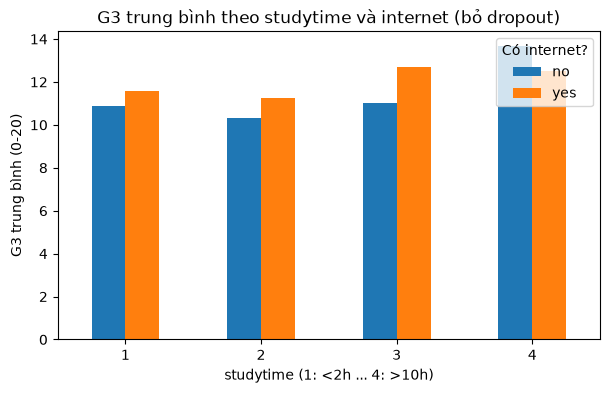

In [13]:
# --- Biểu đồ 1: G3 trung bình theo studytime, tách theo internet (dùng phạm vi bỏ dropout) ---
# pivot_table: hàng = studytime, cột = internet (yes/no), giá trị = G3 trung bình
bang = core.pivot_table(index="studytime", columns="internet", values="G3", aggfunc="mean")

ax = bang.plot(kind="bar", figsize=(7, 4), rot=0)          # rot=0: nhãn trục x nằm ngang
ax.set_title("G3 trung bình theo studytime và internet (bỏ dropout)")
ax.set_xlabel("studytime (1: <2h ... 4: >10h)")
ax.set_ylabel("G3 trung bình (0-20)")
ax.legend(title="Có internet?")
plt.show()

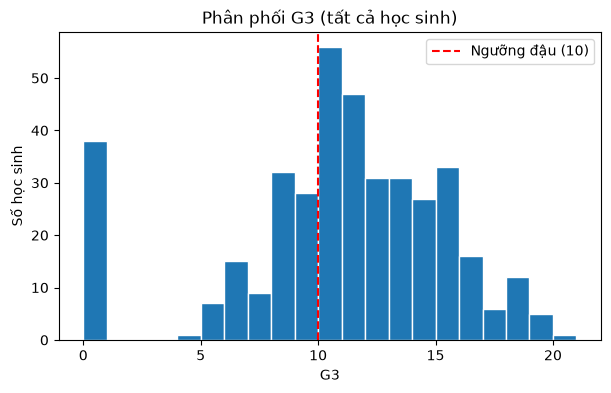

In [14]:
# --- Biểu đồ 2: phân phối G3 (histogram) ---
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(all_students["G3"], bins=range(0, 22), edgecolor="white")   # mỗi cột = 1 điểm nguyên
ax.axvline(10, color="red", linestyle="--", label="Ngưỡng đậu (10)")  # đường dọc đánh dấu điểm đậu
ax.set_title("Phân phối G3 (tất cả học sinh)")
ax.set_xlabel("G3"); ax.set_ylabel("Số học sinh"); ax.legend()
plt.show()

**Đọc kết quả biểu đồ 2:** cột cao bất thường ở G3 = 0 chính là nhóm dropout suspect — một "cục" riêng tách khỏi phần còn lại, vốn tập trung quanh mức trung bình ≈ 11–12 điểm (khi bỏ dropout).

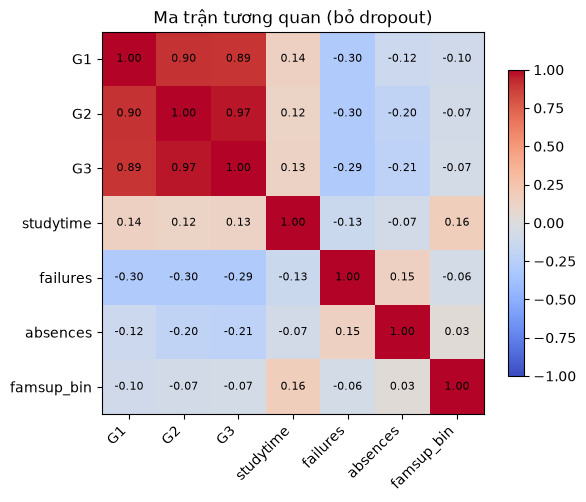

In [15]:
# --- Biểu đồ 3: heatmap tương quan (bỏ dropout) ---
cols = ["G1", "G2", "G3", "studytime", "failures", "absences", "famsup_bin"]
corr = core[cols].corr()          # ma trận hệ số tương quan Pearson (-1 ... +1)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)   # màu đỏ = tương quan dương, xanh = âm
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):                                # ghi số vào từng ô
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Ma trận tương quan (bỏ dropout)")
plt.tight_layout(); plt.show()

## 9. Tương quan G1 / G2 / G3

Hệ số tương quan Pearson `r` đo mức độ **tuyến tính** giữa hai biến, từ −1 đến +1:
- `r` gần **+1**: biến này tăng thì biến kia tăng; gần **0**: gần như không liên quan; gần **−1**: tăng ngược chiều.

Quy ước thô: |r| < 0.3 yếu · 0.3–0.7 vừa · > 0.7 mạnh.

> ⚠ **Tương quan không phải nhân quả.** G2 cao ↔ G3 cao không có nghĩa G2 *gây ra* G3; cả hai cùng phản ánh năng lực học.

In [16]:
# So sánh tương quan G2–G3 và absences–G3 giữa 2 phạm vi
for ten, d in [("all", all_students), ("exclude_dropout", core)]:
    print(f"{ten:16s} | r(G1,G3) = {d['G1'].corr(d['G3']):.2f} "
          f"| r(G2,G3) = {d['G2'].corr(d['G3']):.2f} "
          f"| r(absences,G3) = {d['absences'].corr(d['G3']):+.2f}")

all              | r(G1,G3) = 0.80 | r(G2,G3) = 0.90 | r(absences,G3) = +0.03
exclude_dropout  | r(G1,G3) = 0.89 | r(G2,G3) = 0.97 | r(absences,G3) = -0.21


**Đọc kết quả:** G1 và G2 liên quan G3 rất mạnh (r ≈ 0.80–0.97, tuỳ phạm vi). Quan trọng hơn: `absences–G3` là **+0.03** khi gộp dropout nhưng **−0.21** khi bỏ dropout. Lý do: các em G3 = 0 đều nghỉ 0 buổi (điểm thấp mà nghỉ ít) nên kéo tương quan về gần 0 và *che mất* xu hướng "nghỉ nhiều → điểm thấp hơn một chút". Vẫn là tương quan yếu, nhưng dấu đã đổi → xử lý dropout ảnh hưởng đến kết luận.

## 10. Kiểm định thống kê

Chênh lệch trung bình giữa 2 nhóm có thể chỉ do **ngẫu nhiên**. Kiểm định thống kê trả lời: *"nếu thật ra không có khác biệt, xác suất thấy chênh lệch lớn như thế này là bao nhiêu?"* — đó là **p-value**.

- Quy ước: `p < 0.05` → kết luận "khác biệt có ý nghĩa thống kê".
- **Welch t-test**: so sánh trung bình của **2 nhóm** (vd có/không internet). Không giả định hai nhóm có cùng độ phân tán.
- **One-way ANOVA**: so sánh trung bình của **3 nhóm trở lên** (vd studytime 1–4).
- **Hiệu chỉnh Holm**: khi chạy 7 kiểm định cùng lúc, cơ hội "dính một kết quả có ý nghĩa do may rủi" tăng lên, nên p-value được điều chỉnh lại. Dưới đây ta tính p **thô**; pipeline (phần 12) sẽ có thêm `p_holm`.

In [17]:
# --- Welch t-test: học sinh CÓ internet vs KHÔNG có internet (phạm vi bỏ dropout) ---
g3_co = core.loc[core["internet"] == "yes", "G3"]      # G3 của nhóm có internet
g3_khong = core.loc[core["internet"] == "no", "G3"]    # G3 của nhóm không có

# equal_var=False  → chính là Welch t-test (không giả định phương sai bằng nhau)
ket_qua = stats.ttest_ind(g3_co, g3_khong, equal_var=False)

print(f"n(có)={len(g3_co)}, n(không)={len(g3_khong)}")
print(f"G3 trung bình: có = {g3_co.mean():.2f}, không = {g3_khong.mean():.2f}, chênh = {g3_co.mean() - g3_khong.mean():.2f}")
print(f"t = {ket_qua.statistic:.2f}, p = {ket_qua.pvalue:.4f}")

n(có)=299, n(không)=58
G3 trung bình: có = 11.68, không = 10.71, chênh = 0.98
t = 2.25, p = 0.0268


In [18]:
# --- ANOVA: G3 theo studytime (4 nhóm) ---
# Tạo list gồm G3 của từng nhóm studytime rồi truyền vào f_oneway
nhom = [g["G3"].to_numpy() for _, g in core.groupby("studytime")]
anova = stats.f_oneway(*nhom)       # dấu * "bung" list thành nhiều tham số
print(f"ANOVA studytime: F = {anova.statistic:.2f}, p = {anova.pvalue:.4f}")

# Kích thước hiệu ứng eta² = phần biến thiên của G3 mà studytime giải thích được (0 → 1)
tat_ca = np.concatenate(nhom)
ss_between = sum(len(g) * (g.mean() - tat_ca.mean()) ** 2 for g in nhom)
ss_total = ((tat_ca - tat_ca.mean()) ** 2).sum()
print(f"eta² = {ss_between / ss_total:.3f}   (≈ {ss_between / ss_total:.1%} biến thiên G3 được giải thích)")

ANOVA studytime: F = 4.38, p = 0.0048
eta² = 0.036   (≈ 3.6% biến thiên G3 được giải thích)


**Đọc kết quả (p thô, chưa Holm):** nhớ phân biệt hai khái niệm — *có ý nghĩa thống kê* (p nhỏ) khác với *quan trọng trên thực tế* (hiệu ứng lớn). Với mẫu ~357 học sinh, chênh lệch nhỏ vẫn có thể cho p nhỏ. Hãy nhìn thêm **`diff`** (chênh lệch trung bình) và **`eta²`**, không chỉ nhìn p. Kết quả chính thức sau hiệu chỉnh Holm ở phần 12.

## 11. Quy tắc cảnh báo rủi ro (Risk Group) + holdout

**Mục tiêu thực tế:** phát hiện sớm học sinh có nguy cơ rớt, **trước kỳ thi cuối** để can thiệp. Vì vậy quy tắc chỉ được dùng thông tin có sẵn *trước* kỳ thi: `G1`, `G2`, `failures`, `absences` — **tuyệt đối không dùng G3** (ADR-0002; dùng G3 là gian lận kiểu "biết đáp án trước").

| Nhóm | Điều kiện | Hành động |
|---|---|---|
| `high` | `G2 < 10` **hoặc** `failures ≥ 2` | Can thiệp |
| `medium` | `G1 < 10` hoặc `failures ≥ 1` hoặc nghỉ nhiều (≥10) | Theo dõi |
| `low` | còn lại | Không cần |

In [19]:
print(inspect.getsource(dp.classify_risk))   # xem đúng quy tắc đang dùng

def classify_risk(row: pd.Series) -> str:
    """Early-warning segment from information available before the final exam.

    Uses only G1, G2, failures, absences (never G3, so it can be evaluated
    against pass/fail without leakage).
    high   : G2 < G_WARN or failures >= FAIL_HIGH
    medium : G1 < G_WARN or failures > 0 or absences high (>= ABS_HIGH)
    low    : otherwise
    """
    if row["G2"] < G_WARN or row["failures"] >= FAIL_HIGH:
        return "high"
    if (row["G1"] < G_WARN or row["failures"] > 0
            or classify_absences(row["absences"]) == "high"):
        return "medium"
    return "low"



In [20]:
# apply(..., axis=1) = chạy hàm cho TỪNG DÒNG (mỗi dòng là một học sinh)
all_students = all_students.copy()
all_students["risk_group"] = all_students.apply(dp.classify_risk, axis=1)

# Bảng chéo: mỗi nhóm rủi ro có bao nhiêu học sinh THỰC SỰ rớt?
bang_rui_ro = pd.crosstab(all_students["risk_group"], all_students["pass_fail"])
bang_rui_ro["ti_le_rot"] = (bang_rui_ro["fail"] / bang_rui_ro.sum(axis=1)).round(3)
bang_rui_ro.loc[["low", "medium", "high"]]

pass_fail,fail,pass,ti_le_rot
risk_group,,,
low,2,167,0.012
medium,6,71,0.078
high,122,27,0.819


In [21]:
# Precision & recall của nhóm "high" khi dự đoán "rớt"
du_doan_rot = all_students["risk_group"] == "high"      # quy tắc nói "sẽ rớt"
thuc_te_rot = all_students["pass_fail"] == "fail"       # thực tế rớt

tp = int((du_doan_rot & thuc_te_rot).sum())             # đoán rớt và đúng là rớt
fp = int((du_doan_rot & ~thuc_te_rot).sum())            # đoán rớt nhưng thực ra đậu (báo động nhầm)
fn = int((~du_doan_rot & thuc_te_rot).sum())            # bỏ sót: rớt mà không bị gắn "high"

print(f"TP={tp}, FP={fp}, FN={fn}")
print(f"precision = TP/(TP+FP) = {tp / (tp + fp):.3f}   ← trong số bị gắn 'high', bao nhiêu % thực sự rớt")
print(f"recall    = TP/(TP+FN) = {tp / (tp + fn):.3f}   ← trong số thực sự rớt, bao nhiêu % bị bắt được")

TP=122, FP=27, FN=8
precision = TP/(TP+FP) = 0.819   ← trong số bị gắn 'high', bao nhiêu % thực sự rớt
recall    = TP/(TP+FN) = 0.938   ← trong số thực sự rớt, bao nhiêu % bị bắt được


### Holdout: kiểm tra trên dữ liệu "chưa từng thấy"

Ngưỡng của quy tắc được chọn dựa trên môn Toán, nên đo lại chính trên Toán sẽ *lạc quan*. Cách kiểm tra công bằng: **đóng băng quy tắc** rồi thử trên môn Bồ Đào Nha (`por`) — dữ liệu mà ta không dùng để chọn ngưỡng.

Một số học sinh học cả hai môn (đã "thấy" ở Toán), nên ta còn có phiên bản **strict holdout**: chỉ giữ học sinh `por` *không* xuất hiện trong `mat`, nhận diện bằng 13 cột khoá `MERGE_KEYS`.

In [22]:
# Dữ liệu por (đọc thô rồi tạo các cột cần cho quy tắc)
por = por_raw.copy()
por["pass_fail"] = por["G3"].apply(dp.calc_pass_fail)
por["risk_group"] = por.apply(dp.classify_risk, axis=1)

# Tập "chữ ký" của học sinh Toán: ghép 13 cột khoá thành một tuple cho mỗi học sinh
chu_ky_mat = set(map(tuple, mat_raw[dp.MERGE_KEYS].astype(str).to_numpy()))

# Học sinh por nào có chữ ký trùng → khả năng cao là CÙNG một người đã học Toán
trung = por[dp.MERGE_KEYS].astype(str).apply(tuple, axis=1).isin(chu_ky_mat)
por_strict = por[~trung]
print(f"por: {len(por)} học sinh | trùng với mat: {int(trung.sum())} | strict holdout: {len(por_strict)}")

for ten, d in [("por (toàn bộ)", por), ("por strict (không trùng mat)", por_strict)]:
    ti_le = d.groupby("risk_group")["pass_fail"].apply(lambda s: (s == "fail").mean()).round(3)
    print(f"\n{ten}: tỉ lệ rớt theo nhóm →", ti_le.to_dict())

por: 649 học sinh | trùng với mat: 374 | strict holdout: 275

por (toàn bộ): tỉ lệ rớt theo nhóm → {'high': 0.592, 'low': 0.005, 'medium': 0.079}

por strict (không trùng mat): tỉ lệ rớt theo nhóm → {'high': 0.66, 'low': 0.008, 'medium': 0.098}


**Đọc kết quả:** thứ tự `high > medium > low` về tỉ lệ rớt **vẫn giữ nguyên** trên dữ liệu chưa từng thấy → quy tắc không chỉ "học thuộc" dữ liệu Toán. Tỉ lệ rớt của nhóm `high` thấp hơn trên holdout so với Toán (≈ 66% so với ≈ 82%) là điều bình thường (ngoài mẫu thường kém hơn trong mẫu). Số liệu đầy đủ ở `summary.json`.

## 12. Chạy pipeline đầy đủ & đối chiếu với phần làm tay

Toàn bộ các bước trên đã được đóng gói trong lớp `StudentDataProcessor`:

```
load_data()  →  clean_data()  →  analyze()  →  export_results()
(đọc CSV)       (làm sạch, flag)  (thống kê, test, risk)  (ghi CSV/JSON/ảnh)
```

Đây cũng chính là những gì `python main.py` chạy. Ở đây ta chạy nó với **thư mục đầu ra tạm** để không ghi đè file của project, rồi **đối chiếu** với kết quả phần làm tay — nếu khớp thì phần làm tay của ta đúng.

In [23]:
tmp = Path(tempfile.mkdtemp())     # thư mục tạm, tự nằm ngoài project

proc = dp.StudentDataProcessor(
    raw_paths={"mat": MAT_CSV, "por": POR_CSV},
    pisa_raw=PISA_CSV,
    processed_dir=tmp / "processed",
    images_dir=tmp / "images",
    primary_subject="mat",         # môn phân tích chính
    oecd_raw=OECD_CSV,
)
proc.load_data()                    # bước 1: đọc dữ liệu
clean = proc.clean_data()           # bước 2: làm sạch + gắn cờ bất thường
res = proc.analyze()                # bước 3: thống kê, kiểm định, đánh giá rủi ro (+ vẽ biểu đồ vào thư mục tạm)

print("Đã chạy xong. Số dòng sau làm sạch:", len(clean))
print("Log làm sạch:", {k: v for k, v in proc.cleaning_log.items() if isinstance(v, int)})

Đã chạy xong. Số dòng sau làm sạch: 1044
Log làm sạch: {'rows_in': 1044, 'n_cells_stripped': 0, 'n_duplicates_dropped': 0, 'n_missing_required_dropped': 0, 'rows_out': 1044}


In [24]:
# --- Đối chiếu: số làm tay (phần 5-11) so với pipeline ---
pl_all = res["scopes"]["all"]
pl_core = res["scopes"]["exclude_dropout"]

kiem_tra = {
    "n (all)":                   (len(all_students), pl_all["n"]),
    "n (exclude_dropout)":       (len(core), pl_core["n"]),
    "tỉ lệ đậu (all)":           (round((all_students["G3"] >= 10).mean(), 4), pl_all["pass_rate"]),
    "p Welch internet":          (round(ket_qua.pvalue, 4), pl_core["group_tests"]["internet"]["p"]),
    "precision nhóm high":       (round(tp / (tp + fp), 4), res["risk_eval"]["all"]["high"]["precision"]),
    "recall nhóm high":          (round(tp / (tp + fn), 4), res["risk_eval"]["all"]["high"]["recall"]),
}
for ten, (lam_tay, pipeline) in kiem_tra.items():
    ok = "✔ khớp" if abs(lam_tay - pipeline) < 1e-3 else "✘ LỆCH"
    print(f"{ten:24s} làm tay = {lam_tay:<8} pipeline = {pipeline:<8} {ok}")

n (all)                  làm tay = 395      pipeline = 395      ✔ khớp
n (exclude_dropout)      làm tay = 357      pipeline = 357      ✔ khớp
tỉ lệ đậu (all)          làm tay = 0.6709   pipeline = 0.6709   ✔ khớp
p Welch internet         làm tay = 0.0268   pipeline = 0.0268   ✔ khớp
precision nhóm high      làm tay = 0.8188   pipeline = 0.8188   ✔ khớp
recall nhóm high         làm tay = 0.9385   pipeline = 0.9385   ✔ khớp


In [25]:
# --- Kết quả kiểm định CHÍNH THỨC có hiệu chỉnh Holm (phạm vi bỏ dropout) ---
tests = pd.DataFrame(pl_core["group_tests"]).T
tests[["test", "diff", "p", "p_holm", "eta2", "significant"]]

,test,diff,p,p_holm,eta2,significant
internet,Welch t-test,0.98,0.0268,0.0804,NaN,False
famsup,Welch t-test,-0.45,0.202,0.404,NaN,False
schoolsup,Welch t-test,-2.21,0.000001,0.000003,NaN,True
paid,Welch t-test,-0.19,0.585,0.585,NaN,False
studytime,one-way ANOVA,NaN,0.00482,0.0193,0.036,True
absence_level,one-way ANOVA,NaN,0.000069,0.000343,0.053,True
failures,one-way ANOVA,NaN,0.0,0.000001,0.089,True


**Cách đọc bảng trên:**
- `diff`: chênh lệch G3 trung bình (đơn vị: điểm). `eta2`: kích thước hiệu ứng (chỉ có ở ANOVA).
- `p`: p-value thô. `p_holm`: p đã hiệu chỉnh cho việc chạy nhiều kiểm định cùng lúc.
- `significant = True` chỉ khi **`p_holm < 0.05`**.

Một biến có `p` thô < 0.05 nhưng `p_holm` ≥ 0.05 (ví dụ `internet`) nghĩa là: *chênh lệch có thể chỉ là may rủi khi so sánh nhiều biến* → **không** kết luận có ý nghĩa.

## 13. Dữ liệu tham chiếu PISA (web scraping)

Ngoài dữ liệu học sinh, project còn **cào (scrape) bảng điểm PISA** từ Wikipedia bằng `requests` + `BeautifulSoup`, rồi đối chiếu với bảng OECD chính thức.

Đây chỉ là **bối cảnh cấp quốc gia** (Bồ Đào Nha so với trung bình OECD) — **không bao giờ ghép** với dữ liệu từng học sinh. Mặc định notebook đọc bản cache nên không cần mạng.

In [26]:
pisa = proc.pisa_clean              # bảng PISA đã làm sạch
print("Kích thước:", pisa.shape)
pisa.head()

Kích thước: (1662, 6)


,source,year,subject,rank,country,score
0,comparison,2000,mathematics,1,Hong Kong,560
1,comparison,2000,mathematics,2,Japan,557
2,comparison,2000,mathematics,3,South Korea,547
3,comparison,2000,mathematics,4,New Zealand,537
4,comparison,2000,mathematics,5,Finland,536


In [27]:
# Bồ Đào Nha so với trung bình OECD theo môn & năm (đã tính sẵn trong analyze())
ctx = pd.DataFrame({(mon, int(nam)): v for mon, cac_nam in res["pisa_context"].items()
                    for nam, v in cac_nam.items()}).T
ctx.index.names = ["môn", "năm"]
ctx

portugal  portugal_rank  oecd_average
môn         năm                                        
mathematics 2000       454             23           492
            2003       466             30           499
            2006       466             35           494
            2009       487             31           495
            2012       487             29           494
            2015       492             29           490
            2018       492             28           489
            2022       472             29           472
            2025       460             30           463
reading     2000       470             26           493
            2003       478             28           494
            2006       472             30           489
            2009       489             25           493
            2012       488             31           496
            2015       498             21           493
            2018       492             24           487
            2022       477             24           476
            2025       462             26           461
science     2006       474             36           498
            2009       493             30           501
            2012       489             34           501
            2015       501             23           493
            2018       492             26           489
            2022       484             30           485
            2025       482             29           482

In [28]:
# Đối chiếu bản cào Wikipedia với bảng OECD chính thức (độ tin cậy của dữ liệu cào)
for nam, c in res["pisa_oecd_check"].items():
    if str(nam).isdigit():
        print(f"{nam}: {c['n_within_tolerance']}/{c['n_compared']} nước khớp trong ±{c['tolerance']} điểm "
              f"(khớp chính xác: {c['n_exact']})")

2025: 274/274 nước khớp trong ±0 điểm (khớp chính xác: 274)
2022: 208/211 nước khớp trong ±1 điểm (khớp chính xác: 161)


## 14. Kết luận & hạn chế

### Kết luận chính (môn Toán, sau khi bỏ 38 dropout suspect)
1. **Điểm giữa kỳ (G1, G2) là yếu tố liên quan mạnh nhất đến G3** (r ≈ 0.8–0.9).
2. **`failures`** (từng rớt môn) có liên hệ rõ nhất trong các biến hành vi/lịch sử: G3 trung bình giảm từ ≈ 11.9 (0 lần rớt) xuống ≈ 8.3 (3 lần rớt); ANOVA có ý nghĩa sau Holm (eta² ≈ 0.09).
3. **`studytime`** và **mức nghỉ học (`absence_level`)** có ý nghĩa thống kê sau Holm nhưng **hiệu ứng nhỏ** (eta² ≈ 0.04 và 0.05, tức giải thích chỉ vài % biến thiên của G3).
4. **`internet`, `famsup`, `paid`** **không** có ý nghĩa sau Holm (riêng `internet` có p thô = 0.027 nhưng p_holm = 0.080). `schoolsup = yes` có G3 thấp hơn rõ rệt (≈ −2.2 điểm) — **giả thuyết**: nhà trường hỗ trợ đúng những em đang học kém (nhân quả đảo ngược); dữ liệu này không chứng minh được điều đó.
5. **Xử lý dropout ảnh hưởng đến kết luận** (đặc biệt `absences`: r đổi từ +0.03 sang −0.21), nên luôn báo cáo cả hai phạm vi.
6. **Quy tắc Risk Group** (chỉ dùng thông tin trước kỳ thi cuối) phân tách tốt các mức rủi ro và giữ đúng thứ tự high > medium > low trên dữ liệu holdout (nhóm `high` rớt ≈ 66% trên strict holdout so với ≈ 82% trên Toán).

### Hạn chế (cần nói thật)
- Dữ liệu **quan sát** từ hai trường ở Bồ Đào Nha → chỉ chứng minh *liên hệ*, **không** chứng minh *nhân quả*.
- Chỉ 395 học sinh Toán; nhiều nhóm nhỏ (vd `failures = 3`) nên kết luận ở nhóm đó không chắc chắn.
- `studytime`, `famsup`... do học sinh **tự khai báo** → có thể sai lệch.
- Nguyên nhân thật của `G3 = 0` là **suy luận** (từ `absences = 0`), **chưa được xác nhận** bởi nguồn dữ liệu.
- Holdout `por` là môn khác, cùng hệ thống trường → chưa phải kiểm chứng ở trường/quốc gia khác.

### Bài tập thử nghiệm (tuỳ chọn)
- Đổi ngưỡng đậu trong `dp.THRESHOLDS` (vd 12) và xem phần 5, 11 thay đổi thế nào.
- Chạy lại phần 10 với `famsup` hoặc `paid` thay cho `internet`.
- Thử phạm vi `all` (có dropout) trong phần 10 và so sánh p-value.

### Tài liệu liên quan trong project
`PROJECT_GUIDE.md` (tổng quan) · `METHODS.md` (giải thích từng phương pháp thống kê) · `QA.md` (câu hỏi bảo vệ) · `CONTEXT.md` (thuật ngữ) · `docs/adr/` (quyết định thiết kế).